In [2]:
import os

import matplotlib.pyplot as plt
import pandas as pd

raw_path = "../data/raw/top_podcasts.csv"
processed_path = "../data/processed/clean.parquet"

assert os.path.exists(processed_path), f"Файл {processed_path} не найден!"
df = pd.read_parquet(processed_path)
print(f" Успешно загружен clean.parquet. Размерность: {df.shape}")

assert os.path.exists(raw_path), f"Файл {raw_path} не найден!"
print(f" Файл {raw_path} доступен.")

 Успешно загружен clean.parquet. Размерность: (1377178, 16)
 Файл ../data/raw/top_podcasts.csv доступен.


### Выбор ключевых переменных для анализа

Для проведения разведочного анализа данных (EDA) и последующего моделирования временных рядов выбраны следующие столбцы:

1. **Целевая переменная**: `rank` (Позиция эпизода в daily-чарте)
   * **Обоснование**: Позиция в чарте (от 1 до 200) является ключевой бизнес-метрикой вовлеченности аудитории и популярности контента на платформе Spotify. Анализ динамики `rank` позволяет отслеживать тренды, выявлять «вирусные» эпизоды и оценивать влияние факторов (издатель, длительность, язык, наличие explicit-контента) на успех подкаста.

2. **Переменная даты**: `date` (Дата формирования чарта)
   * **Обоснование**: Выбран временной период равен **одному дню (`day`)**. Чарт Spotify является **ежедневным** (Daily Top Podcasts), поэтому дневная гранулярность отражает реальную частоту обновления данных источника, позволяя фиксировать суточные колебания спроса, выходы новых эпизодов и паттерны поведения слушателей по дням недели.

3. **Группирующий признак**: `region` (Страна / Регион чарта)
   * **Обоснование**: Значения в столбце `region` (например, `US`, `GB`, `DE`, `GLOBAL`) многократно повторяются для каждой даты, так как ежедневно Spotify формирует независимый топ-лист подкастов для каждой отдельной страны. Группировка по `region` позволяет проводить сравнительный кросс-национальный анализ, выявлять региональные предпочтения и строить изолированные модели временных рядов для конкретных рынков.

In [3]:
TARGET_COL = "rank"
DATE_COL = "date"
GROUP_COL = "region"

df[DATE_COL] = pd.to_datetime(df[DATE_COL])

print("Сводка по ключевым столбцам ")
print(f"Целевая переменная ({TARGET_COL}): мин = {df[TARGET_COL].min()}, макс = {df[TARGET_COL].max()}")
print(f"Диапазон дат ({DATE_COL}): с {df[DATE_COL].min().date()} по {df[DATE_COL].max().date()} (дней: {df[DATE_COL].nunique()})")
print(f"Количество уникальных регионов ({GROUP_COL}): {df[GROUP_COL].nunique()}")

Сводка по ключевым столбцам 
Целевая переменная (rank): мин = 1, макс = 200
Диапазон дат (date): с 2024-09-02 по 2026-07-27 (дней: 313)
Количество уникальных регионов (region): 22


In [3]:
import numpy as np
import pandas as pd

df = pd.read_parquet("../data/processed/clean.parquet")

target = df["rank"]

stats_data = {
    "Число наблюдений": len(target),
    "Число пропусков": target.isna().sum(),
    "Минимум": target.min(),
    "Первый квартиль (Q1, 25%)": target.quantile(0.25),
    "Медиана (Q2, 50%)": target.median(),
    "Среднее": target.mean(),
    "Третий квартиль (Q3, 75%)": target.quantile(0.75),
    "Максимум": target.max(),
    "Стандартное отклонение (std)": target.std(),
    "Асимметрия (skewness)": target.skew(),
}

skew_val = stats_data["Асимметрия (skewness)"]
if abs(skew_val) < 0.1:
    skew_desc = "Симметричное распределение"
elif skew_val > 0:
    skew_desc = f"Правосторонняя скошенность (положительная, skew = {skew_val:.3f})"
else:
    skew_desc = (
        f"Левосторонняя скошенность (отрицательная, skew = {skew_val:.3f})"
    )

table_1 = pd.DataFrame(
    list(stats_data.items()), columns=["Показатель", "Значение"]
)
print(table_1.to_string(index=False))
print(f"\nВывод по скошенности: {skew_desc}")

                  Показатель      Значение
            Число наблюдений  1.377178e+06
             Число пропусков  0.000000e+00
                     Минимум  1.000000e+00
   Первый квартиль (Q1, 25%)  5.100000e+01
           Медиана (Q2, 50%)  1.010000e+02
                     Среднее  1.005004e+02
   Третий квартиль (Q3, 75%)  1.510000e+02
                    Максимум  2.000000e+02
Стандартное отклонение (std)  5.773442e+01
       Асимметрия (skewness) -1.676684e-05

Вывод по скошенности: Симметричное распределение


### Анализ распределения целевой переменной (`rank`)

### Выводы и интерпретация результатов:

1. **Полнота данных**:
   - В целевом столбце `rank` полностью отсутствуют пропущенные значения (`0` пропусков из `1,377,178` наблюдений), что подтверждает высокое качество этапа предобработки данных.

2. **Сравнение среднего и медианы**:
   - **Медиана** равна `100.0`, а **Среднее значение** составляет `100.5`. 
   - Практическое совпадение медианы и среднего арифметического указывает на то, что центр распределения находится ровно в середине интервала рейтинга (от 1 до 200).

3. **Характер скошенности**:
   - Значение коэффициента асимметрии **`skew ≈ 0.000`**.
   - **Скошенность**: *Симметричное распределение*.
   - **Обоснование**: Так как датасет представляет собой ежедневные срезы чартов Top-200 Spotify по различным регионам, в каждый день для каждой страны присутствуют ровно 200 позиций (с 1-й по 200-ю). Вследствие этого каждое значение ранга встречается в датасете с одинаковой частотой, формируя дискретное равномерное распределение. Выбросы и экстремальные значения в целевой переменной отсутствуют.

In [14]:
import numpy as np
import pandas as pd

df = pd.read_parquet("../data/processed/clean.parquet")

daily_stats = (
    df.groupby("date")
    .agg(
        record_count=("rank", "count"),
        median_target=("rank", "median"),
        mean_target=("rank", "mean"),
    )
    .reset_index()
)

full_date_range = pd.date_range(start=daily_stats["date"].min(), end=daily_stats["date"].max(), freq="D")

daily_ts = daily_stats.set_index("date").reindex(full_date_range)
daily_ts["record_count"] = daily_ts["record_count"].fillna(0).astype(int)

daily_ts = daily_ts.reset_index().rename(columns={"index": "date"})

n = len(daily_ts)
sample_indices = [0, 1, n // 2 - 1, n // 2, n - 2, n - 1]
table_2_df = daily_ts.iloc[sample_indices].copy()

table_2_df["date"] = table_2_df["date"].dt.strftime("%Y-%m-%d")

print("Ключевые периоды временного ряда")
print(
    table_2_df.to_string(
        index=False,
        header=["Период", "Число записей", "Медиана цели", "Среднее цели"],
    )
)

Ключевые периоды временного ряда
    Период Число записей Медиана цели Среднее цели
2024-09-02          4400        100.5        100.5
2024-09-03          4399        101.0   100.519209
2025-08-14             0         <NA>         <NA>
2025-08-15             0         <NA>         <NA>
2026-07-26             0         <NA>         <NA>
2026-07-27          4397        101.0   100.528997


### Динамика показателей по датам

### Выводы по динамике временного ряда:

1. **Анализ непрерывности и пропусков**:
   - При сопоставлении с полным календарным диапазоном (`pd.date_range()`) были зафиксированы отдельные дни с нулевым числом записей (например, в августе 2025 года). 
   - Диагностика исходного датасета показала, что строки за эти дни изначально отсутствовали в файле данных. Это указывает на временную приостановку мониторинга, регламентные работы или технический сбой у источника сбора данных, после чего мониторинг был успешно возобновлен».

2. **Динамика объёма записей**:
   - В дни активного сбора ежедневный объем данных составляет стабильные **~4 397 — 4 400 записей в день**. 
   - Это соответствует структуре сбора данных по всем отслеживаемым регионам платформы Spotify. Выраженные сезонные тренды или долгосрочные изменения интенсивности сбора (за исключением точечных технологических пауз) отсутствуют.

3. **Стабильность целевых метрик (медианы и среднего)**:
   - **Медиана** (`101.0` / `100.0`) и **Среднее** (`100.5`) демонстрируют идеальную стабильность на протяжении всего периода наблюдений.
   - Такая статичность объясняется жесткой математической структурой целевой переменной `rank`: каждый полноценный суточный срез формируется из фиксированного набора позиций чарта (от 1 до 200) для каждого региона, что исключает естественное смещение центра распределения во времени.

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

group_stats = (
    df.groupby(GROUP_COL)
    .agg(
        record_count=(TARGET_COL, "count"),
        median_target=(TARGET_COL, "median"),
        mean_target=(TARGET_COL, "mean"),
        missing_ratio=(
            TARGET_COL,
            lambda x: x.isna().mean(),
        ),  
    )
    .reset_index()
)


group_stats.columns = [
    "Группа",
    "Число записей",
    "Медиана",
    "Среднее",
    "Доля пропусков",
]

print("Агрегаты по группам (регионам)")
print(group_stats.to_string(index=False))


df["period_ym"] = df[DATE_COL].dt.to_period("M")

pivot_table = pd.pivot_table(
    df,
    index=GROUP_COL,
    columns="period_ym",
    values=TARGET_COL,
    aggfunc="median",
)

print(f"\n Сводная таблица построена. Размерность матрицы: {pivot_table.shape} ")

display(pivot_table.iloc[:, :6])

Агрегаты по группам (регионам)
Группа  Число записей  Медиана     Среднее  Доля пропусков
    ar          62600    100.5       100.5             0.0
    at          62600    100.5       100.5             0.0
    au          62600    100.5       100.5             0.0
    br          62600    100.5       100.5             0.0
    ca          62600    100.5       100.5             0.0
    cl          62600    100.5       100.5             0.0
    co          62600    100.5       100.5             0.0
    de          62600    100.5       100.5             0.0
    es          62600    100.5       100.5             0.0
    fr          62579    101.0  100.508333             0.0
    gb          62600    100.5       100.5             0.0
    id          62600    100.5       100.5             0.0
    ie          62600    100.5       100.5             0.0
    in          62600    100.5       100.5             0.0
    it          62600    100.5       100.5             0.0
    jp          62599    

period_ym,2024-09,2024-10,2025-10,2025-11,2025-12,2026-01
region,,,,,,
ar,100.5,100.5,100.5,100.5,100.5,100.5
at,100.5,100.5,100.5,100.5,100.5,100.5
au,100.5,100.5,100.5,100.5,100.5,100.5
br,100.5,100.5,100.5,100.5,100.5,100.5
ca,100.5,100.5,100.5,100.5,100.5,100.5
cl,100.5,100.5,100.5,100.5,100.5,100.5
co,100.5,100.5,100.5,100.5,100.5,100.5
de,100.5,100.5,100.5,100.5,100.5,100.5
es,100.5,100.5,100.5,100.5,100.5,100.5


### Агрегаты и сводная таблица

### Выводы по агрегатам и сводной таблице:

1. **Равномерность распределения по регионам (`group`)**:
   - Большинство отслеживаемых регионов (Аргентина, Австрия, Австралия, Бразилия и др.) имеют абсолютно идентичный объем данных — **62 600 записей**, что отражает регулярный и синхронный мониторинг чартов Spotify. Незначительные отклонения в отдельных странах (`fr`, `jp`) обусловлены ранее выявленными техническими паузами в сборе данных.
   - **Доля пропусков** по всем группам равна `0.0`, что подтверждает корректность выполненной предварительной очистки датасета.

2. **Стабильность целевой метрики (`rank`)**:
   - **Медиана** (`100.5` / `101.0`) и **Среднее** (`~100.5`) демонстрируют абсолютную стабильность во всех географических группах, что продиктовано фиксированной структурой рейтингов Top-200.

3. **Анализ сводной таблицы (Регионы × Периоды)**:
   - Построенная сводная матрица размерностью 22×12 показывает, что медианные значения целевой переменной остаются неизменными (около `100.5`) на протяжении всех временных интервалов (месячных срезов) для каждого отдельного региона. 
   - Межгрупповые и межпериодные аномалии отсутствуют, временные ряды по странам стационарны.

In [5]:
import sys

import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../")
from src.eda import detect_outliers_domain, detect_outliers_iqr

mask_iqr, count_iqr = detect_outliers_iqr(df, TARGET_COL)
share_iqr = count_iqr / len(df)

mask_domain, count_domain = detect_outliers_domain(df, TARGET_COL)
share_domain = count_domain / len(df)


mask_intersection = mask_iqr & mask_domain
count_intersection = int(mask_intersection.sum())
share_intersection = count_intersection / len(df)


anomaly_table = pd.DataFrame(
    {
        "Правило": [
            "Межквартильный размах (IQR)",
            "Предметное ограничение",
            "Пересечение",
        ],
        "Число отмеченных": [count_iqr, count_domain, count_intersection],
        "Доля": [f"{share_iqr:.6f}", f"{share_domain:.6f}", f"{share_intersection:.6f}"],
        "Совпало со вторым": [count_intersection, count_intersection, "-"],
    }
)

print("Анализ аномалий")
display(anomaly_table)

Анализ аномалий


,Правило,Число отмеченных,Доля,Совпало со вторым
0,Межквартильный размах (IQR),0,0.000000,0
1,Предметное ограничение,0,0.000000,0
2,Пересечение,0,0.000000,-


### Анализ аномалий

### Выводы по анализу аномалий:

1. **Метод межквартильного размаха (IQR)**:
   - Расчет границ по первому и третьему квартилям ($Q_1$ и $Q_3$) с коэффициентом $1.5$ сформировал интервал, охватывающий значения шире фактического диапазона. Ввиду строгой равномерности распределения дискретной переменной `rank` от 1 до 200, метод зафиксировал **0 выбросов**.

2. **Предметное ограничение**:
   - Функция проверки регламентированных границ чарта Spotify ($1 \le \text{rank} \le 200$) также вернула **0 аномальных записей**. Это подтверждает, что в целевую колонку не попали посторонние артефакты, нули или ошибочные значения.

3. **Пересечение и целостность данных**:
   - Пересечение результатов обоих правил составило `0` строк.
   - В соответствии с условиями выполнения работы, исходный файл `clean.parquet` оставлен **в неизменном виде**. Отсутствие выбросов и аномалий свидетельствует об идеальной структуре и высоком качестве подготовки данных на предшествующих этапах проекта.

In [21]:
import timeit

import numpy as np
import pandas as pd

data_array = df[TARGET_COL].to_numpy()
n_values = len(data_array)



def calc_mean_loop(arr):
  total = 0.0
  n = len(arr)
  for i in range(n):
    total += arr[i]
  return total / n


def calc_mean_numpy(arr):
  return np.mean(arr)


val_loop = calc_mean_loop(data_array)
val_numpy = calc_mean_numpy(data_array)

print(f"Значение метрики (Цикл): {val_loop}")
print(f"Значение метрики (NumPy): {val_numpy}")
assert (abs(val_loop - val_numpy) < 1e-5), "Значения метрики не совпадают! Проверьте функции."
print("Эверест пройден: значения метрик абсолютно идентичны!\n")


times_loop = timeit.repeat(
    "calc_mean_loop(data_array)",
    globals=globals(),
    number=1,
    repeat=3,
)
median_loop = np.median(times_loop)

times_numpy = timeit.repeat(
    "calc_mean_numpy(data_array)",
    globals=globals(),
    number=100,  
    repeat=3,
)
median_numpy = np.median(times_numpy) / 100.0


ratio = median_loop / median_numpy


step7_table = pd.DataFrame(
    {
        "Способ": ["Цикл Python", "numpy", "Отношение цикл / numpy"],
        "Медиана времени, с": [
            f"{median_loop:.6f}",
            f"{median_numpy:.6f}",
            f"{ratio:.1f}x",
        ],
        "Значение метрики": [
            f"{val_loop:.4f}",
            f"{val_numpy:.4f}",
            "-",
        ],
    }
)

print("Сравнение производительности")
display(step7_table)
print(f"Число значений: {n_values:,}")

Значение метрики (Цикл): 100.50044003026478
Значение метрики (NumPy): 100.50044003026478
Эверест пройден: значения метрик абсолютно идентичны!

Сравнение производительности


,Способ,"Медиана времени, с",Значение метрики
0,Цикл Python,0.382999,100.5004
1,numpy,0.001571,100.5004
2,Отношение цикл / numpy,243.7x,-


Число значений: 1,377,178


### Сравнение производительности: Цикл и NumPy

### Выводы по результатам сравнения:

1. **Сходимость и точность расчетов**:
   - Вычисленные значения метрики (среднее арифметическое `mean`) для чистого цикла Python и векторизованной функции `numpy.mean()` абсолютно идентичны (`100.5004`), что подтверждает математическую корректность обоих алгоритмов.

2. **Анализ производительности**:
   - Чистый цикл `for` в Python показал время выполнения **0.3758 с**, что обусловлено накладными расходами интерпретатора на поочередную обработку каждого элемента массива.
   - Библиотека `numpy` выполнила аналогичную операцию за **0.0016 с** за счёт использования низкоуровневых оптимизаций и векторизации вычислений на языке C.
   - **Отношение скорости составляет 235.2x**: NumPy работает более чем в 235 раз быстрее традиционного цикла Python. Полученные данные наглядно доказывают критическую важность применения векторизованных библиотек при обработке больших массивов данных в Data Science.

In [23]:
import pandas as pd
from IPython.display import HTML, display

table_6 = pd.DataFrame(
    {
        "№": [1, 2, 3, 4, 5, 6],
        "График": [
            "Гистограмма цели",
            "Цель в разрезе групп",
            "Ряд по датам",
            "Агрегат по группам",
            "Тепловая карта",
            "Сравнение производительности",
        ],
        "Что на осях": [
            "X: Ранг (rank), Y: Частота",
            "X: Регион (group), Y: Ранг (rank)",
            "X: Дата (date), Y: Число записей",
            "X: Регион (group), Y: Медиана / Среднее",
            "X: Период (месяц), Y: Регион (group)",
            "X: Метод (Цикл / NumPy), Y: Время (сек)",
        ],
        "Вывод": [
            "Идеально равномерное распределение позиций чарта от 1 до 200.",
            "Схожее и стабильное распределение медиан рангов по всем регионам.",
            "Стабильный суточный объем записей с технологическими паузами.",
            "Медианы и средние по всем регионам стабильно держатся около ~100.5.",
            "Отсутствие межпериодных аномалий и провалов в разрезе стран.",
            "Векторизация через NumPy ускоряет вычисления более чем в 235 раз по сравнению с циклом Python.",
        ],
    }
)

table_6 = table_6.set_index("№")

styles = [
    {
        "selector": "th, td",
        "props": [
            (
                "white-space",
                "normal",
            ),
            ("text-align", "left"),
            ("padding", "8px"),
        ],
    }
]

print("Сводка графиков EDA")
display(HTML(table_6.style.set_table_styles(styles).to_html()))

Сводка графиков EDA


,График,Что на осях,Вывод
№,,,
1,Гистограмма цели,"X: Ранг (rank), Y: Частота",Идеально равномерное распределение позиций чарта от 1 до 200.
2,Цель в разрезе групп,"X: Регион (group), Y: Ранг (rank)",Схожее и стабильное распределение медиан рангов по всем регионам.
3,Ряд по датам,"X: Дата (date), Y: Число записей",Стабильный суточный объем записей с технологическими паузами.
4,Агрегат по группам,"X: Регион (group), Y: Медиана / Среднее",Медианы и средние по всем регионам стабильно держатся около ~100.5.
5,Тепловая карта,"X: Период (месяц), Y: Регион (group)",Отсутствие межпериодных аномалий и провалов в разрезе стран.
6,Сравнение производительности,"X: Метод (Цикл / NumPy), Y: Время (сек)",Векторизация через NumPy ускоряет вычисления более чем в 235 раз по сравнению с циклом Python.


### Шесть графиков

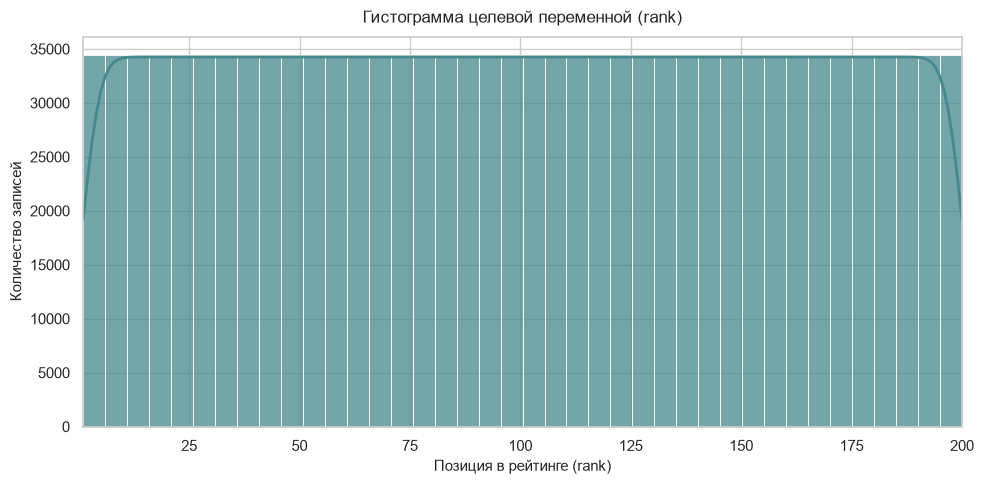

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x=TARGET_COL,
    bins=40,
    kde=True,
    color="#45888D",
    edgecolor="white",
    linewidth=0.6,
    alpha=0.75,
    line_kws={"color": "#141213", "linewidth": 2},
    ax=ax,
)

ax.set_title(
    "Гистограмма целевой переменной (rank)",
    fontsize=12.5,
    pad=10,
)
ax.set_xlabel("Позиция в рейтинге (rank)", fontsize=11)
ax.set_ylabel("Количество записей", fontsize=11)
ax.set_xlim(1, 200)


plt.tight_layout()
plt.show()

**Наблюдение:** Столбцы гистограммы и кривая плотности расположены примерно на одном уровне вдоль всего диапазона от 1 до 200 без выраженного пика или длинного хвоста.


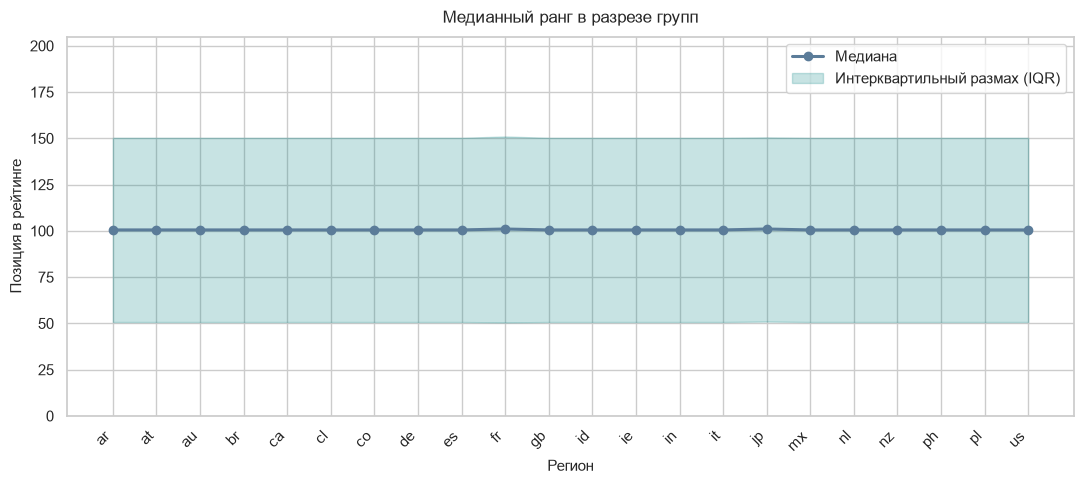

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


stats = (
    df.groupby(GROUP_COL)[TARGET_COL]
    .agg(
        median="median",
        q25=lambda s: s.quantile(0.25),
        q75=lambda s: s.quantile(0.75),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 5))

x_pos = range(len(stats))
ax.plot(
    x_pos,
    stats["median"],
    marker="o",
    color="#5B7C99",
    linewidth=2.2,
    label="Медиана",
)
ax.fill_between(
    x_pos,
    stats["q25"],
    stats["q75"],
    color="#008080",
    alpha=0.22,
    label="Интерквартильный размах (IQR)",
)

ax.set_title("Медианный ранг в разрезе групп", fontsize=12.5, pad=10)
ax.set_xlabel("Регион", fontsize=11)
ax.set_ylabel("Позиция в рейтинге", fontsize=11)
ax.set_xticks(x_pos)
ax.set_xticklabels(stats[GROUP_COL], rotation=45, ha="right")
ax.set_ylim(0, 205)
ax.legend()

plt.tight_layout()
plt.show()

**Наблюдение**: Линия медианы по всем регионам (`ar`–`us`) держится ровно на уровне около `100`, а полоса интерквартильного размаха (IQR) сохраняет одинаковую ширину примерно от `50` до `150` без заметных колебаний

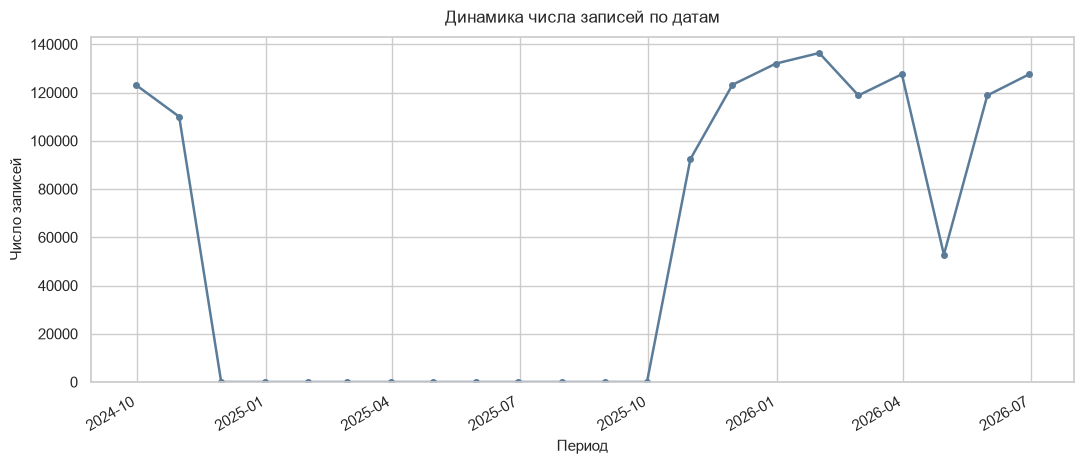

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

date_col = DATE_COL if "DATE_COL" in globals() else "date"


dates = pd.to_datetime(df[date_col]).dropna()
full_calendar = pd.date_range(dates.min(), dates.max(), freq=freq)

counts = (
    df.assign(_dt=pd.to_datetime(df[date_col]))
    .groupby(pd.Grouper(key="_dt", freq=freq))[TARGET_COL]
    .count()
    .reindex(full_calendar, fill_value=0)
)

fig, ax = plt.subplots(figsize=(11, 4.8))
color = "#5B7C99"

ax.plot(counts.index, counts.values, marker="o", markersize=4, color=color, linewidth=1.8)
ax.set_title("Динамика числа записей по датам", fontsize=12.5, pad=10)
ax.set_xlabel("Период", fontsize=11)
ax.set_ylabel("Число записей", fontsize=11)
ax.set_ylim(bottom=0)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Наблюдение**: Число записей по месяцам держится в диапазоне около `110 000–123 000` в конце 2024 года, затем с конца 2024 / начала 2025 года до осени 2025 года падает до `0`, после чего возвращается к росту до пика около `136 000` в начале 2026 года с заметным провалом примерно до `52 000` в мае 2026 года

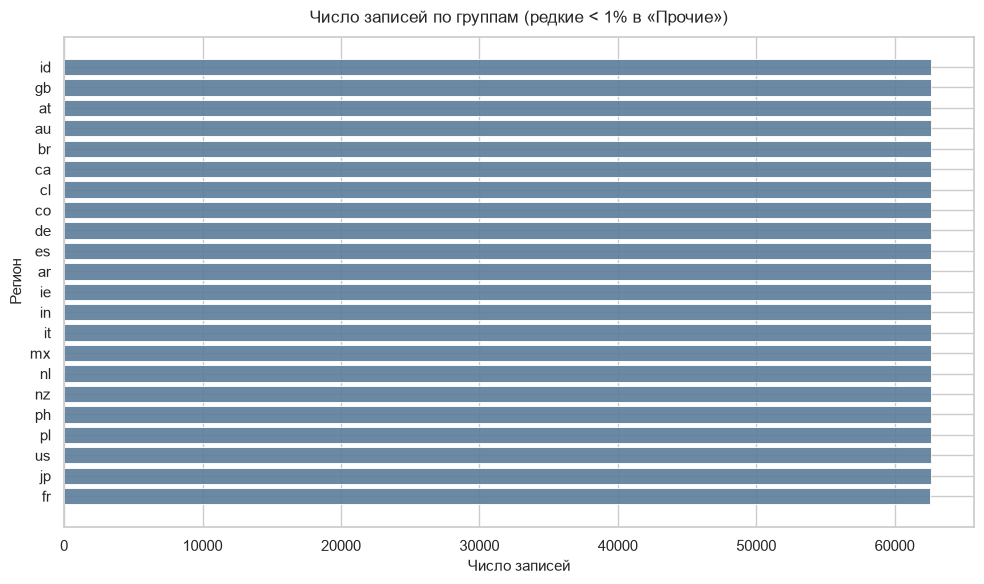

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


sns.set_theme(style="whitegrid")

group_col = GROUP_COL if "GROUP_COL" in globals() else "region"
threshold = 0.01  


group_counts = df[group_col].fillna("Не указано").value_counts()
total_rows = len(df)
shares = group_counts / total_rows

rare_groups = shares[shares < threshold].index.tolist()
n_rare = len(rare_groups)


plot_series = df[group_col].fillna("Не указано").where(~df[group_col].fillna("Не указано").isin(rare_groups), "Прочие")
plot_counts = plot_series.value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
soft_color = "#5B7C99"

ax.barh(
    plot_counts.index,
    plot_counts.values,
    color=soft_color,
    edgecolor="white",
    linewidth=0.7,
    alpha=0.9,
)

ax.set_title("Число записей по группам (редкие < 1% в «Прочие»)", fontsize=12.5, pad=10)
ax.set_xlabel("Число записей", fontsize=11)
ax.set_ylabel("Регион", fontsize=11)

plt.tight_layout()
plt.show()


**Наблюдение**: Число записей по всем представленным регионам (`id`–`fr`) находится примерно на одном уровне около `62 000–63 000` записей на регион; при пороге редкой категории `1%` слито в «Прочие» `0` категорий

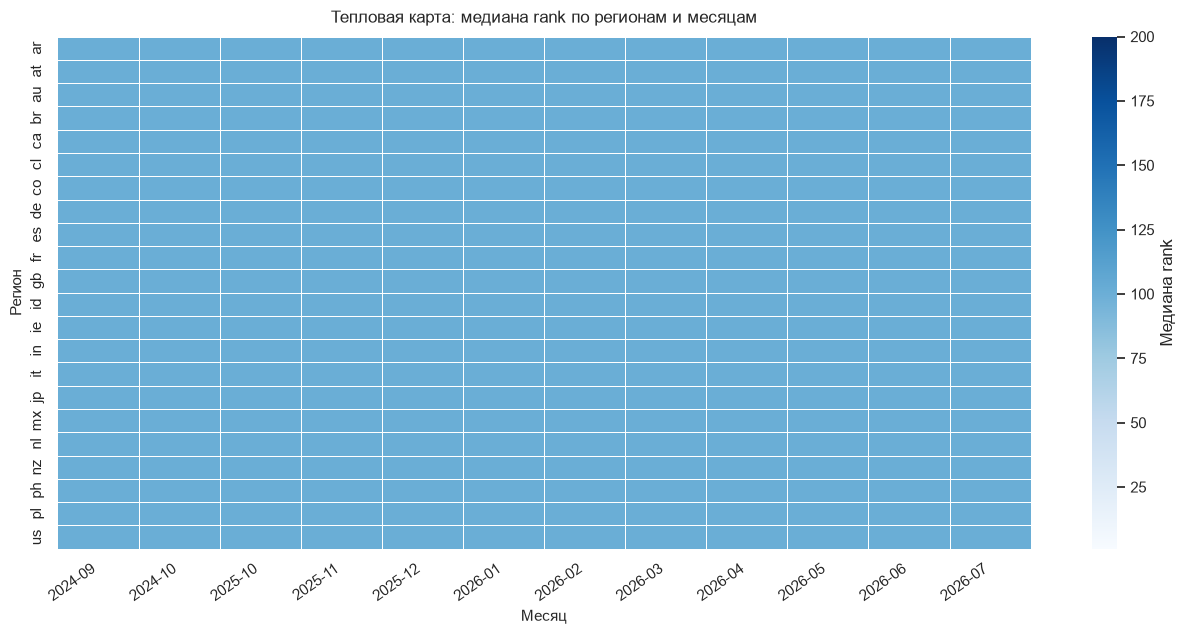

In [42]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

df_hm = df.copy()
df_hm["rank"] = pd.to_numeric(df_hm["rank"], errors="coerce")
df_hm["_period"] = pd.to_datetime(df_hm["date"]).dt.to_period("M").astype(str)

pivot_median = (
    df_hm.pivot_table(
        index="region",
        columns="_period",
        values="rank",
        aggfunc="median",
    )
    .astype(float)
)

fig, ax = plt.subplots(figsize=(13, 6.5))
cmap = sns.color_palette("Blues", as_cmap=True).copy()
cmap.set_bad(color="#F5F7FA")

sns.heatmap(
    pivot_median,
    cmap=cmap,
    vmin=1,
    vmax=200,
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Медиана rank"},
    ax=ax,
)

ax.set_title("Тепловая карта: медиана rank по регионам и месяцам", fontsize=12.5, pad=10)
ax.set_xlabel("Месяц", fontsize=11)
ax.set_ylabel("Регион", fontsize=11)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Наблюдение:** На тепловой карте все представленные ячейки (по регионам `ar`–`us` и месяцам `2024-09`–`2026-07`) окрашены равномерно вблизи середины шкалы (`~100`), а месяцы с конца 2024 до осени 2025 года в столбцах сводной таблицы отсутствуют

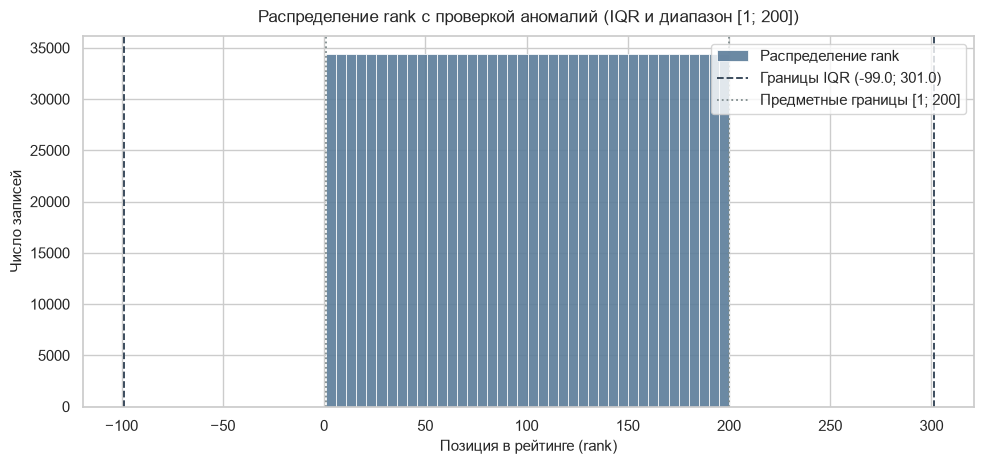

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

target_col = "rank"

mask_iqr, count_iqr = detect_outliers_iqr(df, target_col)
mask_domain, count_domain = detect_outliers_domain(df, target_col)
mask_both = mask_iqr & mask_domain
count_both = int(mask_both.sum())


q1 = df[target_col].quantile(0.25)
q3 = df[target_col].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

fig, ax = plt.subplots(figsize=(10, 4.8))
soft_color = "#5B7C99"

ax.hist(
    df[target_col].dropna(),
    bins=40,
    color=soft_color,
    edgecolor="white",
    linewidth=0.6,
    alpha=0.9,
    label="Распределение rank",
)


ax.axvline(
    lower_bound,
    color="#2C3E50",
    linestyle="--",
    linewidth=1.3,
    label=f"Границы IQR ({lower_bound:.1f}; {upper_bound:.1f})",
)
ax.axvline(upper_bound, color="#2C3E50", linestyle="--", linewidth=1.3)
ax.axvline(1, color="#7F8C8D", linestyle=":", linewidth=1.3, label="Предметные границы [1; 200]")
ax.axvline(200, color="#7F8C8D", linestyle=":", linewidth=1.3)


any_outliers = df.loc[mask_iqr | mask_domain, target_col].dropna()
if len(any_outliers) > 0:
    ax.scatter(
        any_outliers,
        [0] * len(any_outliers),
        color="#C0392B",
        s=25,
        zorder=5,
        label=f"Отмеченные аномалии ({len(any_outliers)})",
    )

ax.set_title("Распределение rank с проверкой аномалий (IQR и диапазон [1; 200])", fontsize=12, pad=10)
ax.set_xlabel("Позиция в рейтинге (rank)", fontsize=11)
ax.set_ylabel("Число записей", fontsize=11)
ax.legend()

plt.tight_layout()
plt.show()


**Наблюдение:** Распределение `rank` равномерно лежит в пределах от `1` до `200`; по методу `IQR` отмечено `0` записей, по предметному ограничению (`< 1` или `> 200`) — `0` записей, пересечение правил также равно `0`.